# Sift - a classical spam classifier, end to end

**Word + character TF-IDF -> logistic regression -> precision-weighted cut-off**

This notebook walks through the model the Django API serves. It covers data
cleaning, the leak-free split, the two feature views, model comparison, the
false-positive-capped threshold, test metrics, explainability, and the external
SpamAssassin check.

### Contents

1. [The dataset](#1-the-dataset)
2. [Cleaning and leak-free splitting](#2-cleaning-and-leak-free-splitting)
3. [Feature engineering](#3-feature-engineering)
4. [Candidate models](#4-candidate-models)
5. [Choosing a decision threshold](#5-choosing-a-decision-threshold)
6. [Final test evaluation](#6-final-test-evaluation)
7. [Explainability](#7-explainability)
8. [The production artifact](#8-the-production-artifact)
9. [Limitations and next steps](#9-limitations-and-next-steps)

> **Runtime note.** A full training run takes about 11 minutes. This notebook
> uses a stratified **14,000-message sample** (`DEMO_ROWS`) so it stays quick.
> Set `DEMO_ROWS = None` to use the full clean corpus. The production numbers in
> section 8 are read from `ml/artifacts/metrics.json`, so they are the real
> artifact numbers, not the sample estimate. The sample can also pick a
> different winning family than the full run; section 8 always uses the
> deployed artifact.


In [1]:
import gc
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

# Find the repository root from any launch directory.
ROOT = Path.cwd()
while not (ROOT / "ml").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from ml.data import load_dataset, split_dataset
from ml.evaluate import (
    binary_metrics,
    choose_threshold,
    length_bucket,
    metrics_by_group,
    predict_scores,
    top_features,
)
from ml.features import build_feature_union, normalize_text
from ml.predict import load_metrics, load_model, predict_many, predict_text

DATA_PATH = ROOT / "combined_data.csv"
SMS_PATH = ROOT / "data" / "sms_spam.zip"
SPAMASSASSIN_DIR = ROOT / "data" / "spamassassin"
ARTIFACT_DIR = ROOT / "ml" / "artifacts"

DEMO_ROWS = 14_000
RANDOM_STATE = 7
MAX_VALIDATION_FPR = 0.005
SELECTION_TOLERANCE = 0.003

SPAM = "#C96F4F"
HAM = "#6B7F5B"
INK = "#2E3A2F"
SAND = "#D9C9B2"
plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": SAND,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlesize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": INK,
        "ytick.color": INK,
        "text.color": INK,
        "font.family": "DejaVu Sans",
        "figure.dpi": 120,
        "figure.figsize": (9, 4),
    }
)

print("Repository:", ROOT)
print("Main dataset:", DATA_PATH.exists())
print("SMS data:", SMS_PATH.exists())
print("SpamAssassin data:", SPAMASSASSIN_DIR.exists())


Repository: D:\Code-Base\Git-Clones\Spam-classifire
Main dataset: True
SMS data: True
SpamAssassin data: True


## 1. The dataset

The main corpus is `combined_data.csv` with **83,448 raw messages** (76,127
after cleaning):

| column | meaning |
| --- | --- |
| `text` | the raw message body |
| `label` | `1` = spam, `0` = ham |

The project also supports the UCI SMS Spam Collection for short messages. When
`data/sms_spam.zip` exists, training adds **5,574 raw SMS rows** (5,118 after
cleaning). The merged corpus has **89,022 raw rows** and **81,245 clean rows**.

The API exposes the readable labels `"spam"` and `"ham"`. The numeric form is
only used by the model.


In [2]:
raw = pd.read_csv(DATA_PATH, usecols=["label", "text"])
raw["text"] = raw["text"].astype(str)

print(f"Main rows: {len(raw):,}")
print(f"Nulls: {raw.isna().sum().to_dict()}")
print("Label counts:", raw["label"].value_counts().to_dict())
print("Exact duplicate texts:", int(raw["text"].duplicated().sum()))
display(raw.head(3))

lengths = raw["text"].str.len()
print(
    "Characters - mean: {:.0f} | median: {:.0f} | p95: {:.0f} | max: {:,}".format(
        lengths.mean(), lengths.median(), lengths.quantile(0.95), lengths.max()
    )
)


Main rows: 83,448
Nulls: {'label': 0, 'text': 0}
Label counts: {1: 43910, 0: 39538}
Exact duplicate texts: 2


,label,text
0,1,ounce feather bowl hummingbird opec moment ala...
1,1,wulvob get your medircations online qnb ikud v...
2,0,computer connection from cnn com wednesday es...


Characters - mean: 1663 | median: 879 | p95: 4899 | max: 598,705


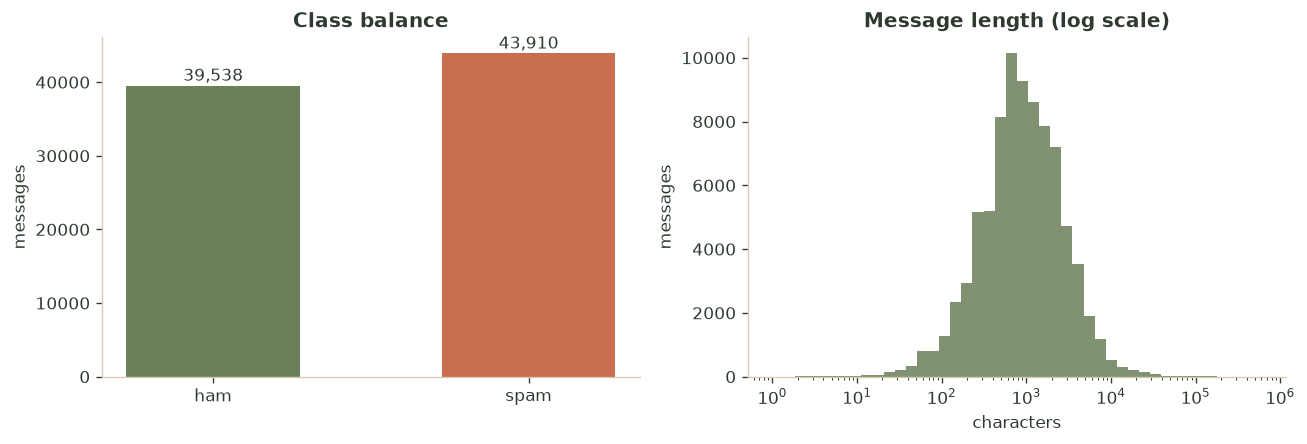

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

counts = raw["label"].map({0: "ham", 1: "spam"}).value_counts().reindex(["ham", "spam"])
axes[0].bar(counts.index, counts.values, color=[HAM, SPAM], width=0.55)
axes[0].set_title("Class balance")
axes[0].set_ylabel("messages")
for index, value in enumerate(counts.values):
    axes[0].text(index, value + counts.max() * 0.015, f"{value:,}", ha="center", fontsize=10)

bins = np.logspace(0, np.log10(lengths.clip(lower=1).max()), 45)
axes[1].hist(lengths.clip(lower=1), bins=bins, color=HAM, alpha=0.85)
axes[1].set_xscale("log")
axes[1].set_title("Message length (log scale)")
axes[1].set_xlabel("characters")
axes[1].set_ylabel("messages")
plt.tight_layout()
plt.show()

del raw, lengths
_ = gc.collect()


### Cleaning decisions

Spam corpora contain the same campaign many times. If a near-identical message
lands in both training and test, the test score is inflated. `ml.data.load_dataset`
therefore:

- normalizes text: lowercase, strip HTML, mask URLs and email addresses, remove
  standalone numbers and years, and collapse whitespace;
- removes **exact duplicates** after case and punctuation normalization;
- removes **near duplicates** with a 64-bit SimHash over word 3-shingles and LSH
  banding (Hamming distance <= 3);
- keeps the first occurrence in a deterministic order.

The deployed model does **not** use length, word-length, casing, line-count, or
punctuation statistics. An external check showed those features transferred
poorly and made short messages look like spam. `TextStats` remains available for
ablations, but it is off by default.


In [4]:
extra = [SMS_PATH] if SMS_PATH.exists() else []
started = time.perf_counter()
dataset = load_dataset(
    DATA_PATH,
    extra_data=extra,
    sample=DEMO_ROWS,
    drop_near_duplicates=True,
    random_state=RANDOM_STATE,
)
print(f"Load + clean: {time.perf_counter() - started:.1f}s")

stats = dataset.stats
display(
    pd.DataFrame(
        {
            "value": [
                stats["rows_loaded"],
                stats["rows_clean"],
                stats["exact_duplicates_removed"],
                stats["near_duplicates_removed"],
                stats["label_counts"]["ham"],
                stats["label_counts"]["spam"],
                stats["text_length"]["median"],
                stats["text_length"]["max"],
            ]
        },
        index=[
            "rows loaded",
            "clean rows used (sample)",
            "exact duplicates removed",
            "near duplicates removed",
            "ham",
            "spam",
            "median characters",
            "max characters",
        ],
    )
)
print("Sources:", stats["sources"])
display(dataset.X.head(2).to_frame("text"))


Loaded 89,022 rows -> 14,000 clean rows (1,129 exact and 6,597 near duplicates removed)
Labels: ham=7,096 spam=6,904
Sources: {'combined_data': 13090, 'sms_spam': 910}
Load + clean: 35.3s


,value
rows loaded,89022
clean rows used (sample),14000
exact duplicates removed,1129
near duplicates removed,6597
ham,7096
spam,6904
median characters,758
max characters,20000


Sources: {'combined_data': 13090, 'sms_spam': 910}


,text
0,suffolk desuetude neither airstrip babe chick ...
1,Mm so you asked me not to call radio


## 2. Cleaning and leak-free splitting

The split is stratified **80/10/10** (train / validation / test) and happens
before any vectorizer is fitted.

- The vectorizers learn vocabulary and IDF weights only from the training fold.
- The validation fold selects the model and threshold.
- The test fold is touched once, at the very end.

Fitting a `TfidfVectorizer` on the whole dataset first would leak test-set
vocabulary into training and produce an optimistic score.


In [5]:
split = split_dataset(dataset, random_state=RANDOM_STATE)
print(split.summary())


def preview(text: str, limit: int = 420) -> str:
    text = "".join(ch if ch.isprintable() or ch in "\n\t" else " " for ch in text)
    return text[:limit] + ("..." if len(text) > limit else "")


for name, part in [("SPAM", 1), ("HAM", 0)]:
    examples = split.X_train[split.y_train == part].head(1).tolist()
    print(f"\n{name} example:\n{preview(examples[0])}")


{'train': 11200, 'validation': 1400, 'test': 1400}

SPAM example:
g ' day
would you reflnance if you knew you ' d save thousands ?
we ' ll get you lnterest as low as 3 . 97 % .
don ' t believe me ? fill out our small online form and we ' ll show you how .
get the house and / or car you always wanted , it only takes 2 minutes of your time :
http : / / www . . com

HAM example:
Er yep sure. Props?


## 3. Feature engineering

The deployed model uses two views:

| view | configuration | why |
| --- | --- | --- |
| **Word TF-IDF** | 1-2 grams, 150k features, `min_df=2`, sublinear TF | phrases such as "click here", "act now", "unclaimed prize" |
| **Character TF-IDF** | `char_wb` 3-5 grams, 80k features, `min_df=5`, first 4,000 characters | obfuscation such as `fr33 m0ney`, `V1AGRA` |

The union weights the word view at `1.0` and the character view at `0.2`, so
character patterns help without drowning the words. Total feature space:
**230,000**. Dense text statistics are not used.

For a term $t$ in document $d$, sublinear TF-IDF is

$$
\mathrm{tf}(t,d) = 1 + \log c(t,d), \qquad
\mathrm{idf}(t) = \log\frac{1 + N}{1 + \mathrm{df}(t)} + 1,
\qquad
w(t,d) = \mathrm{tf}(t,d)\cdot\mathrm{idf}(t).
$$


In [6]:
union = build_feature_union()
X_train = union.fit_transform(split.X_train, split.y_train)
X_val = union.transform(split.X_val)
X_test = union.transform(split.X_test)

print(f"Train matrix: {X_train.shape[0]:,} rows x {X_train.shape[1]:,} features")
print(f"Non-zero values: {X_train.nnz / 1e6:.1f}M ({X_train.nnz / X_train.shape[0]:.0f} per message)")
print(f"Average density: {X_train.nnz / (X_train.shape[0] * X_train.shape[1]):.4%}")

widths = {
    "word": len(union.transformer_list[0][1].get_feature_names_out()),
    "char": len(union.transformer_list[1][1].get_feature_names_out()),
}
display(pd.Series(widths, name="features").to_frame())

samples = [
    "Get 50% OFF before 2026-12-31! Visit https://example.com now.",
    "Hi team, the meeting is at 10:00. Thanks, Sam",
]
display(pd.DataFrame({"raw": samples, "normalized": [normalize_text(text) for text in samples]}))


Train matrix: 11,200 rows x 230,000 features
Non-zero values: 14.5M (1296 per message)
Average density: 0.5635%


,features
word,150000
char,80000


,raw,normalized
0,Get 50% OFF before 2026-12-31! Visit https://e...,get % off before ! visit urltoken now.
1,"Hi team, the meeting is at 10:00. Thanks, Sam","hi team, the meeting is at . thanks, sam"


### A quick look at vocabulary

The plot below is exploratory, not the model. It compares word and bigram
frequencies between spam and ham in the training split. Additive smoothing (+1)
keeps rare terms from dominating.


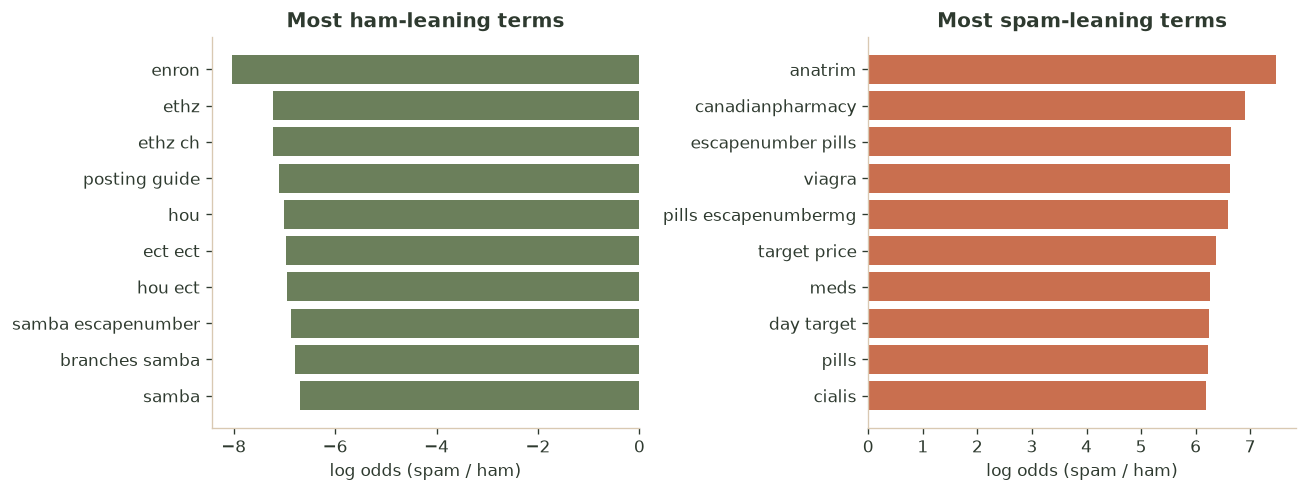

In [7]:
counter = CountVectorizer(
    ngram_range=(1, 2),
    min_df=5,
    max_features=40_000,
    stop_words="english",
)
counts = counter.fit_transform(split.X_train)
names = counter.get_feature_names_out()
y_train_array = split.y_train.to_numpy()

spam_counts = np.asarray(counts[y_train_array == 1].sum(axis=0)).ravel()
ham_counts = np.asarray(counts[y_train_array == 0].sum(axis=0)).ravel()
spam_rate = (spam_counts + 1) / (spam_counts.sum() + len(names))
ham_rate = (ham_counts + 1) / (ham_counts.sum() + len(names))
log_odds = np.log(spam_rate) - np.log(ham_rate)

spam_top = np.argsort(log_odds)[-10:][::-1]
ham_top = np.argsort(log_odds)[:10]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].barh([names[i] for i in ham_top][::-1], log_odds[ham_top][::-1], color=HAM)
axes[0].set_title("Most ham-leaning terms")
axes[0].set_xlabel("log odds (spam / ham)")

axes[1].barh([names[i] for i in spam_top][::-1], log_odds[spam_top][::-1], color=SPAM)
axes[1].set_title("Most spam-leaning terms")
axes[1].set_xlabel("log odds (spam / ham)")
plt.tight_layout()
plt.show()


## 4. Candidate models

Three classical families are compared on validation:

1. **Logistic regression** (`liblinear`, L2, `C=0.25`) - strong sparse-text
   baseline, native probabilities, and one coefficient per feature.
2. **Calibrated Linear SVC** (`C=0.5`, sigmoid calibration, 3 folds) - can be a
   little sharper at the boundary.
3. **Complement Naive Bayes** (`alpha=0.3`) - very fast and a useful sanity
   check.

Selection uses **average precision (PR-AUC)**. If two candidates are within
`0.003` PR-AUC, the project prefers the simpler, more strongly regularised
model instead of chasing a noise-level gain.

On the full production run the SVC lead was `0.0022`, below the tolerance, so
the deployed model is logistic regression. On this smaller sample the gap can
be larger, so the notebook may select the calibrated SVC. That is expected; the
production section always reads the real artifact and its metrics.


In [8]:
candidates = {
    "Logistic regression (C=0.25)": LogisticRegression(
        C=0.25, solver="liblinear", max_iter=2000, random_state=RANDOM_STATE
    ),
    "Calibrated Linear SVC (C=0.5)": CalibratedClassifierCV(
        estimator=LinearSVC(C=0.5, dual="auto", random_state=RANDOM_STATE),
        method="sigmoid",
        cv=3,
    ),
    "Complement NB (alpha=0.3)": ComplementNB(alpha=0.3),
}

rows = []
fitted = {}
val_scores = {}
thresholds = {}

for name, estimator in candidates.items():
    started = time.perf_counter()
    estimator.fit(X_train, split.y_train)
    fit_seconds = time.perf_counter() - started

    scores = predict_scores(estimator, X_val)
    threshold = choose_threshold(
        split.y_val, scores, beta=0.5, max_fpr=MAX_VALIDATION_FPR
    )
    metrics = binary_metrics(split.y_val, scores, threshold)

    fitted[name] = estimator
    val_scores[name] = scores
    thresholds[name] = threshold
    rows.append(
        {
            "model": name,
            "threshold": threshold,
            "precision": metrics["precision"],
            "recall": metrics["recall"],
            "f1": metrics["f1"],
            "f0_5": metrics["f0_5"],
            "pr_auc": metrics["average_precision"],
            "roc_auc": metrics["roc_auc"],
            "false_positive_rate": metrics["false_positive_rate"],
            "fit_s": round(fit_seconds, 2),
        }
    )

comparison = pd.DataFrame(rows).sort_values("pr_auc", ascending=False).reset_index(drop=True)
best_pr = comparison.loc[0, "pr_auc"]
tied = comparison[comparison["pr_auc"] >= best_pr - SELECTION_TOLERANCE]
preferred = "Logistic regression (C=0.25)"
best_name = preferred if preferred in set(tied["model"]) else tied.iloc[0]["model"]
best_clf = fitted[best_name]
best_threshold = thresholds[best_name]
best_val_scores = val_scores[best_name]

display(comparison.round(4))
print(f"Best PR-AUC: {best_name}")
print(f"Selected model: {best_name} at threshold {best_threshold:.4f}")


,model,threshold,precision,recall,f1,f0_5,pr_auc,roc_auc,false_positive_rate,fit_s
0,Calibrated Linear SVC (C=0.5),0.8884,0.9952,0.8928,0.9412,0.9728,0.9966,0.9968,0.0042,2.22
1,Complement NB (alpha=0.3),0.8000,0.9951,0.8826,0.9355,0.9704,0.9941,0.9942,0.0042,0.05
2,Logistic regression (C=0.25),0.6493,0.9944,0.7739,0.8704,0.9408,0.9926,0.9930,0.0042,1.94


Best PR-AUC: Calibrated Linear SVC (C=0.5)
Selected model: Calibrated Linear SVC (C=0.5) at threshold 0.8884


## 5. Choosing a decision threshold

A classifier returns a score; a threshold turns it into a decision. The default
0.5 is rarely the right cut-off for spam. A false positive (real mail marked
spam) is more damaging than a false negative, so the project maximises
**F$_{0.5}$**:

$$
F_\beta = (1+\beta^2)\frac{\mathrm{precision}\cdot\mathrm{recall}}{\beta^2\cdot\mathrm{precision}+\mathrm{recall}},
\qquad \beta = 0.5.
$$

The threshold is chosen on validation, subject to a validation false-positive
rate of at most **0.5%**, then frozen for the test split. The scan uses observed
validation score quantiles, not an arbitrary grid.


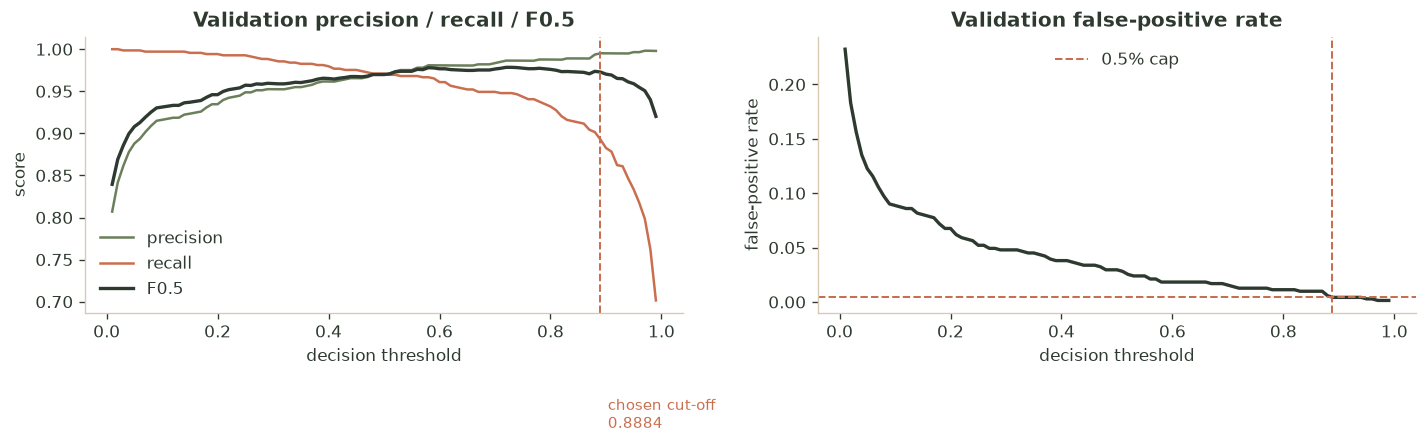

In [9]:
from sklearn.metrics import fbeta_score, precision_score, recall_score

grid = np.linspace(0.01, 0.99, 99)
curve = []
y_val = split.y_val.to_numpy()
for threshold in grid:
    decisions = (best_val_scores >= threshold).astype(int)
    false_positive_rate = ((decisions == 1) & (y_val == 0)).sum() / max((y_val == 0).sum(), 1)
    curve.append(
        (
            threshold,
            precision_score(split.y_val, decisions, zero_division=0),
            recall_score(split.y_val, decisions, zero_division=0),
            fbeta_score(split.y_val, decisions, beta=0.5, zero_division=0),
            false_positive_rate,
        )
    )
curve = pd.DataFrame(
    curve, columns=["threshold", "precision", "recall", "f0_5", "false_positive_rate"]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(curve["threshold"], curve["precision"], color=HAM, label="precision")
axes[0].plot(curve["threshold"], curve["recall"], color=SPAM, label="recall")
axes[0].plot(curve["threshold"], curve["f0_5"], color=INK, linewidth=2, label="F0.5")
axes[0].axvline(best_threshold, color=SPAM, linestyle="--", linewidth=1.2)
axes[0].text(best_threshold + 0.015, 0.55, f"chosen cut-off\n{best_threshold:.4f}", fontsize=9, color=SPAM)
axes[0].set_xlabel("decision threshold")
axes[0].set_ylabel("score")
axes[0].set_title("Validation precision / recall / F0.5")
axes[0].legend(frameon=False, loc="lower left")

axes[1].plot(curve["threshold"], curve["false_positive_rate"], color=INK, linewidth=2)
axes[1].axhline(MAX_VALIDATION_FPR, color=SPAM, linestyle="--", linewidth=1.2, label="0.5% cap")
axes[1].axvline(best_threshold, color=SPAM, linestyle="--", linewidth=1.2)
axes[1].set_xlabel("decision threshold")
axes[1].set_ylabel("false-positive rate")
axes[1].set_title("Validation false-positive rate")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()


## 6. Final test evaluation

The chosen model and threshold are applied **once** to the held-out test split.
The confusion matrix is the clearest summary: false positives are real messages
incorrectly blocked; false negatives are spam that reached the inbox.

The demo sample is smaller than the production run, so these figures are a
little noisier than the artifact's real numbers in section 8.


,test score
threshold,0.8884
accuracy,0.9400
precision,0.9967
recall,0.8812
f1,0.9354
f0_5,0.9712
pr_auc,0.9975
roc_auc,0.9976
brier,0.0197


,tn,fp,fn,tp
0,708,2,82,608


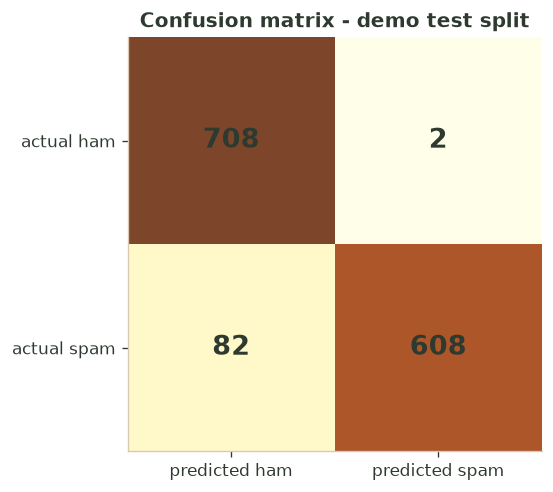

,threshold,accuracy,precision,recall,f1,f0_5,roc_auc,average_precision,brier,confusion_matrix,false_positive_rate,false_negative_rate,support
long (500+ chars),0.8884,0.9614,1.0,0.9172,0.9568,0.9823,0.9997,0.9996,0.0077,"{'tn': 511, 'fp': 0, 'fn': 37, 'tp': 410}",0.0,0.0828,"{'ham': 511, 'spam': 447}"
medium (160-499 chars),0.8884,0.9324,1.0,0.8902,0.9419,0.9759,0.9988,0.9992,0.0173,"{'tn': 108, 'fp': 0, 'fn': 19, 'tp': 154}",0.0,0.1098,"{'ham': 108, 'spam': 173}"
short (<160 chars),0.8884,0.8261,0.9565,0.6286,0.7586,0.8661,0.949,0.9383,0.0954,"{'tn': 89, 'fp': 2, 'fn': 26, 'tp': 44}",0.022,0.3714,"{'ham': 91, 'spam': 70}"


,threshold,accuracy,precision,recall,f1,f0_5,roc_auc,average_precision,brier,confusion_matrix,false_positive_rate,false_negative_rate,support
combined_data,0.8884,0.9413,1.0,0.886,0.9395,0.9749,0.9993,0.9993,0.0139,"{'tn': 644, 'fp': 0, 'fn': 78, 'tp': 606}",0.0,0.114,"{'ham': 644, 'spam': 684}"
sms_spam,0.8884,0.9167,0.5,0.3333,0.4,0.4545,0.9066,0.5614,0.1266,"{'tn': 64, 'fp': 2, 'fn': 4, 'tp': 2}",0.0303,0.6667,"{'ham': 66, 'spam': 6}"


In [10]:
demo_pipeline = Pipeline([("features", union), ("clf", best_clf)])
demo_pipeline.threshold_ = best_threshold
demo_pipeline.version_ = "notebook-demo"

test_scores = predict_scores(best_clf, X_test)
test_metrics = binary_metrics(split.y_test, test_scores, best_threshold)

summary = pd.Series(
    {
        "threshold": test_metrics["threshold"],
        "accuracy": test_metrics["accuracy"],
        "precision": test_metrics["precision"],
        "recall": test_metrics["recall"],
        "f1": test_metrics["f1"],
        "f0_5": test_metrics["f0_5"],
        "pr_auc": test_metrics["average_precision"],
        "roc_auc": test_metrics["roc_auc"],
        "brier": test_metrics["brier"],
    }
)
display(summary.round(4).to_frame("test score"))
display(pd.DataFrame([test_metrics["confusion_matrix"]]))

cm = np.array(
    [
        [test_metrics["confusion_matrix"]["tn"], test_metrics["confusion_matrix"]["fp"]],
        [test_metrics["confusion_matrix"]["fn"], test_metrics["confusion_matrix"]["tp"]],
    ]
)

fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.imshow(cm, cmap="YlOrBr", alpha=0.85)
ax.set_xticks([0, 1], labels=["predicted ham", "predicted spam"])
ax.set_yticks([0, 1], labels=["actual ham", "actual spam"])
for row in range(2):
    for col in range(2):
        ax.text(
            col,
            row,
            f"{cm[row, col]:,}",
            ha="center",
            va="center",
            fontsize=16,
            fontweight="bold",
            color=INK,
        )
ax.set_title("Confusion matrix - demo test split")
plt.tight_layout()
plt.show()

length_groups = [length_bucket(int(length)) for length in split.X_test.str.len()]
source_groups = split.source_test if split.source_test is not None else ["unknown"] * len(split.X_test)
display(pd.DataFrame(metrics_by_group(split.y_test, test_scores, length_groups, best_threshold)).T.round(4))
display(pd.DataFrame(metrics_by_group(split.y_test, test_scores, source_groups, best_threshold)).T.round(4))


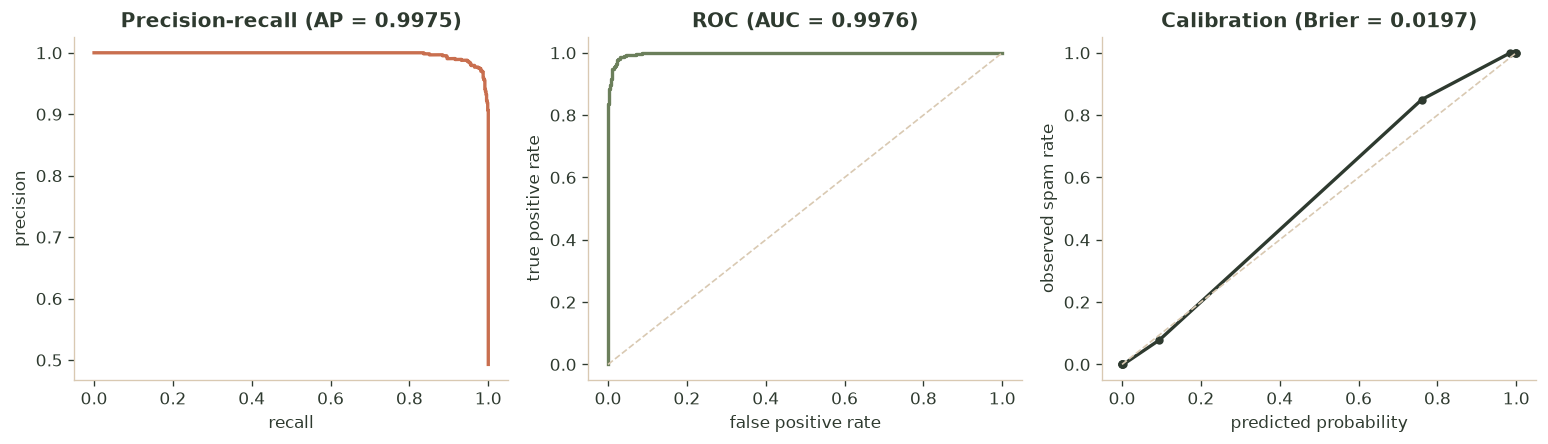

In [11]:
precision_curve, recall_curve, _ = precision_recall_curve(split.y_test, test_scores)
fpr, tpr, _ = roc_curve(split.y_test, test_scores)
prob_true, prob_pred = calibration_curve(split.y_test, test_scores, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

axes[0].plot(recall_curve, precision_curve, color=SPAM, linewidth=2)
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title(f"Precision-recall (AP = {test_metrics['average_precision']:.4f})")

axes[1].plot(fpr, tpr, color=HAM, linewidth=2)
axes[1].plot([0, 1], [0, 1], color=SAND, linestyle="--", linewidth=1)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title(f"ROC (AUC = {test_metrics['roc_auc']:.4f})")

axes[2].plot(prob_pred, prob_true, marker="o", color=INK, linewidth=2, markersize=4)
axes[2].plot([0, 1], [0, 1], color=SAND, linestyle="--", linewidth=1)
axes[2].set_xlabel("predicted probability")
axes[2].set_ylabel("observed spam rate")
axes[2].set_title(f"Calibration (Brier = {test_metrics['brier']:.4f})")

plt.tight_layout()
plt.show()


## 7. Explainability

A linear model's decision is a sum of signed feature contributions:

$$
c_j = w_j \cdot x_j.
$$

Positive contributions push toward spam; negative contributions pull toward ham.
The API returns the largest-magnitude contributions for every single-message
prediction, which is why the UI can show the words that moved the decision.

Global coefficients answer a different question: which features are spammy in
general? They are useful but can be misleading because a word's weight is the
residual association after all other features are considered.


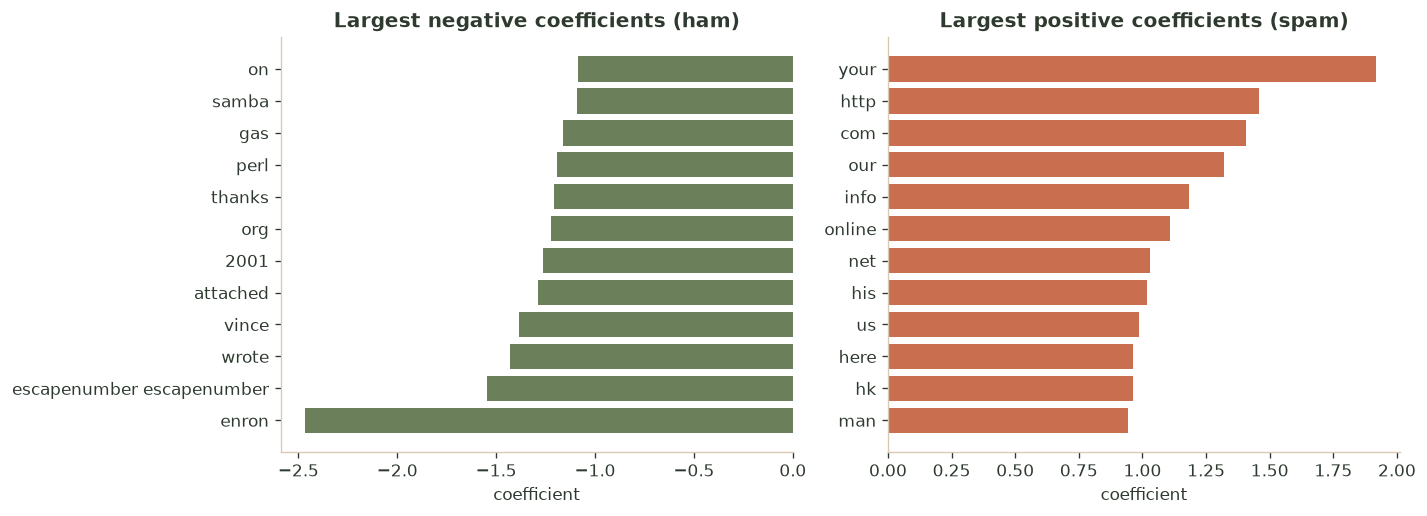

In [12]:
def pretty_feature(name: str) -> str:
    name = str(name)
    if name.startswith("~"):
        return "char:" + name[1:].replace(" ", "_")
    return name


global_signals = top_features(demo_pipeline, n=12)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, key, color, title in [
    (axes[0], "ham", HAM, "Largest negative coefficients (ham)"),
    (axes[1], "spam", SPAM, "Largest positive coefficients (spam)"),
]:
    rows = global_signals[key]
    labels = [pretty_feature(row["word"]) for row in rows][::-1]
    values = [row["weight"] for row in rows][::-1]
    ax.barh(labels, values, color=color)
    ax.set_title(title)
    ax.set_xlabel("coefficient")
plt.tight_layout()
plt.show()


In [13]:
examples = {
    "Phishing / prize": (
        "Congratulations! You have won a free cash prize. Click here immediately "
        "to claim your money before this offer expires."
    ),
    "Legitimate work mail": (
        "Hi Maya, the design review moved to Thursday at 10:00. Could you send "
        "the updated copy before then? Thanks, Sam"
    ),
    "Short casual message": "Hey, did you see the game last night?",
    "Promotional newsletter": (
        "This week only: 30% off all courses. Use code LEARN30 at checkout. "
        "Unsubscribe at any time."
    ),
}

for label, text in examples.items():
    result = predict_text(demo_pipeline, text, threshold=best_threshold, top_n=6)
    display(
        Markdown(
            f"**{label}** -> `{result['label']}` "
            f"({result['spam_probability']:.1%} spam, cut-off {result['threshold']:.4f})"
        )
    )
    display(pd.DataFrame(result["top_words"]))


**Phishing / prize** -> `spam` (100.0% spam, cut-off 0.8884)

,word,weight
0,claim,0.1244
1,your,0.1228
2,money,0.0965
3,to claim,0.0902
4,prize,0.0884
5,here,0.0838


**Legitimate work mail** -> `ham` (1.6% spam, cut-off 0.8884)

,word,weight
0,thanks,-0.1276
1,thursday,-0.1118
2,review,-0.0531
3,the,-0.0470
4,the updated,-0.0462
5,design,0.0449


**Short casual message** -> `ham` (7.0% spam, cut-off 0.8884)

,word,weight
0,last night,-0.1470
1,see,0.1244
2,night,-0.1214
3,did you,-0.1133
4,you see,0.1056
5,last,-0.0764


**Promotional newsletter** -> `ham` (1.4% spam, cut-off 0.8884)

,word,weight
0,unsubscribe,-0.1104
1,at,-0.0760
2,code,-0.0747
3,any,-0.0538
4,this week,-0.0505
5,use,-0.0466


## 8. The production artifact

The demo above uses a sample. The deployed artifact was trained by `ml.train` on
the full clean corpus and refit on train + validation.

The production model is:

- `LogisticRegression(C=0.25, solver="liblinear", max_iter=2000)`
- word TF-IDF + character TF-IDF, no dense statistics
- threshold `0.7219`, chosen on validation with an FPR cap of 0.5%

The metrics below come from `ml/artifacts/metrics.json`, so they are the real
artifact numbers. The external SpamAssassin result is reported separately and
was not used for selection or tuning.


In [14]:
production_metrics = load_metrics(ARTIFACT_DIR / "metrics.json")
production_test = production_metrics["test"]["at_tuned_threshold"]
production_at_05 = production_metrics["test"]["at_0.5"]
external = production_metrics["external"]["at_tuned_threshold"]

production_table = pd.DataFrame(
    {
        f"cut-off {production_metrics['model']['threshold']:.4f}": [
            production_test["accuracy"],
            production_test["precision"],
            production_test["recall"],
            production_test["f1"],
            production_test["f0_5"],
            production_test["average_precision"],
            production_test["roc_auc"],
            production_test["brier"],
        ],
        "default 0.5000": [
            production_at_05["accuracy"],
            production_at_05["precision"],
            production_at_05["recall"],
            production_at_05["f1"],
            production_at_05["f0_5"],
            production_at_05["average_precision"],
            production_at_05["roc_auc"],
            production_at_05["brier"],
        ],
    },
    index=["accuracy", "precision", "recall", "F1", "F0.5", "PR-AUC", "ROC-AUC", "Brier"],
)
display(production_table.round(4))

display(
    pd.DataFrame(production_metrics["comparison"])[
        ["name", "precision", "recall", "f1", "f0_5", "average_precision", "fit_seconds"]
    ].round(4)
)

external_table = pd.Series(
    {
        "accuracy": external["accuracy"],
        "precision": external["precision"],
        "recall": external["recall"],
        "f1": external["f1"],
        "f0_5": external["f0_5"],
        "roc_auc": external["roc_auc"],
        "average_precision": external["average_precision"],
        "false_positive_rate": external["false_positive_rate"],
    }
)
display(external_table.round(4).to_frame("SpamAssassin"))

print("Test confusion matrix:", production_test["confusion_matrix"])
print("External confusion matrix:", external["confusion_matrix"])
print("Artifact:", production_metrics.get("artifact"))
print("Batch latency:", f"{production_metrics.get('latency_ms_per_email', 0):.2f} ms/email")


,cut-off 0.7219,default 0.5000
accuracy,0.9351,0.9710
precision,0.9940,0.9616
recall,0.8732,0.9799
F1,0.9297,0.9707
F0.5,0.9672,0.9652
PR-AUC,0.9962,0.9962
ROC-AUC,0.9964,0.9964
Brier,0.0370,0.0370


,name,precision,recall,f1,f0_5,average_precision,fit_seconds
0,CalibratedLinearSVC,0.9953,0.9561,0.9753,0.9872,0.9988,9.75
1,LogisticRegression,0.9945,0.8609,0.9229,0.9646,0.9966,13.89
2,ComplementNB,0.9943,0.8805,0.9339,0.9693,0.9946,0.17


,SpamAssassin
accuracy,0.9372
precision,0.8995
recall,0.8702
f1,0.8846
f0_5,0.8935
roc_auc,0.9738
average_precision,0.9410
false_positive_rate,0.0372


Test confusion matrix: {'tn': 4114, 'fp': 21, 'fn': 506, 'tp': 3484}
External confusion matrix: {'tn': 3937, 'fp': 152, 'fn': 203, 'tp': 1361}
Artifact: {'path': 'spam_pipeline.joblib', 'size_mb': 4.15}
Batch latency: 2.65 ms/email


In [15]:
production_model = load_model()
print("Loaded version:", production_model.version_)
print("Stored threshold:", production_model.threshold_)

for label, text in examples.items():
    result = predict_text(production_model, text, top_n=6)
    display(
        Markdown(
            f"**{label}** -> `{result['label']}` at "
            f"**{result['spam_probability']:.2%}** spam probability "
            f"(model {result['model_version']})"
        )
    )

if SPAMASSASSIN_DIR.exists():
    from ml.external import evaluate_external, load_spamassassin

    external_dataset = load_spamassassin(SPAMASSASSIN_DIR)
    external_result = evaluate_external(
        production_model,
        external_dataset,
        threshold=float(production_model.threshold_),
    )
    display(pd.Series(external_result["at_tuned_threshold"]).to_frame("live external check"))
    print("External dataset:", external_result["dataset"]["label_counts"])
else:
    print("SpamAssassin corpus not downloaded; using the stored external metrics above.")

warmup = split.X_test.iloc[:50].tolist()
predict_many(production_model, warmup)
timed_texts = split.X_test.iloc[:200].tolist()
started = time.perf_counter()
predict_many(production_model, timed_texts)
elapsed = time.perf_counter() - started
print(f"\nBatch inference: {elapsed * 1000 / len(timed_texts):.2f} ms/message over {len(timed_texts)} messages")


Loaded version: 2.1.0
Stored threshold: 0.7219


**Phishing / prize** -> `spam` at **94.96%** spam probability (model 2.1.0)

**Legitimate work mail** -> `ham` at **20.51%** spam probability (model 2.1.0)

**Short casual message** -> `ham` at **35.13%** spam probability (model 2.1.0)

**Promotional newsletter** -> `ham` at **23.62%** spam probability (model 2.1.0)

,live external check
threshold,0.7219
accuracy,0.9372
precision,0.8995
recall,0.8702
f1,0.8846
f0_5,0.8935
roc_auc,0.9738
average_precision,0.941
brier,0.1365
confusion_matrix,"{'tn': 3937, 'fp': 152, 'fn': 203, 'tp': 1361}"


External dataset: {'ham': 4089, 'spam': 1564}



Batch inference: 1.47 ms/message over 200 messages


## 9. Limitations and next steps

**Known limitations**

- **Dataset drift.** The corpus is a merged public dataset. Vocabulary and
  campaigns change, so a production filter needs monitoring and retraining.
- **Short messages are weak.** On the test split, messages under 160 characters
  have 84.3% accuracy but only 62.3% recall. SMS-style messages are harder still:
  the SMS source slice has 51.3% recall. The threshold is conservative, so many
  short spam messages are missed rather than blocking real mail.
- **External FPR is higher.** SpamAssassin precision is 89.95% and FPR is 3.72%,
  worse than the in-dataset test. That is why the external check is reported
  separately.
- **Residual corpus vocabulary.** Top ham coefficients still include names and
  project terms such as `enron`, `debian`, `perl`, and `samba`. Some of that is
  legitimate context; some is source fingerprinting.
- **No headers, attachments, or sender reputation.** The model reads the body
  only. Real mail security also needs SPF/DKIM, link reputation, and user
  feedback.
- **Threshold trade-off.** The tuned cut-off is precision-first. It is not a
  claim of perfection.

**Useful next steps**

1. Collect user feedback ("mark as spam" / "not spam") and retrain with it.
2. Add a review queue for borderline scores.
3. Rebuild the artifact in CI and compare precision/recall before promoting.
4. Add authentication and per-user rate limits before exposing the API.
5. Try a small amount of domain adaptation if short-message recall matters.

### Reproduce

```bash
# From the repository root, with the virtual environment active
python -m ml.train
jupyter lab ml/notebooks/spam_classifier.ipynb
```

The notebook is executed top-to-bottom; plots and tables above are stored
outputs. Set `DEMO_ROWS = None` to run the walkthrough on the full corpus.
